# Problem 4: Credit Card Default Prediction
## Part 3: Final Holdout Evaluation

**Candidate:** Chetsadaphon Kanthiya 
**Dataset:** UCI Default of Credit Card Clients (30,000 records) 

---

## Workflow summary
Load the feature set selected by training-only cross-validation in notebook 2, recreate and verify the same stratified 70/30 split, choose the cost threshold from training out-of-fold predictions, then evaluate the selected model on the holdout. Also report the pre-specified LightGBM-versus-logistic ROC-AUC comparison, calibration, SHAP, and demographic-group metrics.

## 1. Setup & Load Data

In [1]:
# โหลดเครื่องมือประเมินโมเดล อธิบายผล และตรวจ fairness
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import json
import shap
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
 average_precision_score, brier_score_loss, confusion_matrix, classification_report, roc_auc_score,
 precision_recall_curve, roc_curve, auc
)

# Import preprocessing
sys.path.append('.')
from preprocessing import load_and_clean_data, engineer_features, select_features

SEED = 42
np.random.seed(SEED)
OUTPUT_DIR = os.path.abspath('output')
DATA_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'data')
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'models')
RESULTS_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'results')
for output_dir in (DATA_OUTPUT_DIR, MODEL_OUTPUT_DIR, RESULTS_OUTPUT_DIR):
 os.makedirs(output_dir, exist_ok=True)

print(" Libraries imported")

 Libraries imported


In [2]:
# เตรียมข้อมูลทดสอบพร้อมตัวแปรประชากรสำหรับการตรวจกลุ่ม
# Load and prepare data
df_raw = load_and_clean_data('data/default of credit card clients.xls')
df_engineered = engineer_features(df_raw)

# Keep demographics for fairness analysis
demographics = df_raw[['SEX', 'AGE', 'EDUCATION', 'MARRIAGE']].copy()

# Load the training-CV-selected feature list; the holdout is not used to select features.
X_full, y_full = select_features(df_engineered)
with open(os.path.join(RESULTS_OUTPUT_DIR, 'selected_features.json'), encoding='utf-8') as file:
 feature_selection = json.load(file)
selected_features = feature_selection['selected_features']
missing_features = [name for name in selected_features if name not in X_full.columns]
if missing_features:
 raise ValueError(f'Selected features are missing from the prepared data: {missing_features}')
X_full = X_full.loc[:, selected_features].copy()

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test, demo_train, demo_test = train_test_split(
 X_full, y_full, demographics, test_size=0.30, random_state=SEED, stratify=y_full
)
y_train = np.asarray(y_train)
y_test = np.asarray(y_test)

# Verify that the final holdout is the same one created in notebook 1.
saved_X_test_all = pd.read_csv(os.path.join(DATA_OUTPUT_DIR, 'holdout_features.csv'))
saved_y_test = pd.read_csv(os.path.join(DATA_OUTPUT_DIR, 'holdout_target.csv'))['default'].to_numpy()
if any(name not in saved_X_test_all.columns for name in selected_features):
 raise ValueError('Selected features are missing from the saved holdout CSV.')
saved_X_test = saved_X_test_all.loc[:, selected_features]
if list(X_test.columns) != list(saved_X_test.columns) or X_test.shape != saved_X_test.shape:
 raise ValueError('Saved holdout feature schema does not match the reproducible split.')
if not np.allclose(X_test.to_numpy(dtype=float), saved_X_test.to_numpy(dtype=float), rtol=1e-12, atol=1e-12):
 raise ValueError('Saved holdout features do not match the reproducible split.')
if not np.array_equal(y_test, saved_y_test):
 raise ValueError('Saved holdout labels do not match the reproducible split.')

print(f" Dataset loaded: {df_engineered.shape}")
print(f" Train: {len(y_train):,}, Test: {len(y_test):,}")
print(f" Selected feature set: {feature_selection['selected_feature_set']}")
print(f" Features ({len(X_full.columns)}): {list(X_full.columns)}")

 Dataset loaded: (30000, 30)
 Train: 21,000, Test: 9,000
 Selected feature set: core_plus_num_delays
 Features (14): ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT6', 'PAY_AMT1', 'AGE', 'EDUCATION', 'SEX', 'NUM_DELAYS']


## 2. Load Trained Models

In [3]:
# โหลดโมเดลที่ชนะจาก CV พร้อม baseline และ scaler
comparison_df = pd.read_csv(os.path.join(RESULTS_OUTPUT_DIR, 'cross_validation_model_comparison.csv'))
selected_model_name = comparison_df.sort_values('ROC-AUC', ascending=False).iloc[0]['Model']
model_files = {
 'Logistic Regression': 'logistic_regression_model.pkl',
 'Decision Tree': 'decision_tree_model.pkl',
 'LightGBM': 'lightgbm_model.pkl',
 'XGBoost': 'xgboost_model.pkl',
}
with open(os.path.join(MODEL_OUTPUT_DIR, model_files[selected_model_name]), 'rb') as f:
 selected_model = pickle.load(f)
with open(os.path.join(MODEL_OUTPUT_DIR, 'lightgbm_model.pkl'), 'rb') as f:
 lgb_model = pickle.load(f)
with open(os.path.join(MODEL_OUTPUT_DIR, 'logistic_regression_model.pkl'), 'rb') as f:
 lr_model = pickle.load(f)
with open(os.path.join(MODEL_OUTPUT_DIR, 'feature_scaler.pkl'), 'rb') as f:
 scaler = pickle.load(f)

# Threshold selection uses training OOF predictions, never holdout labels.
oof_predictions = pd.read_csv(os.path.join(RESULTS_OUTPUT_DIR, 'training_oof_predictions.csv'))
if not np.array_equal(oof_predictions['y_true'].to_numpy(), y_train):
 raise ValueError('OOF labels do not match the training split.')
oof_column = {
 'Logistic Regression': 'lr_proba', 'Decision Tree': 'dt_proba',
 'LightGBM': 'lgb_proba', 'XGBoost': 'xgb_proba',
}[selected_model_name]
thresholds = np.linspace(0.0, 1.0, 201)
selected_oof_probs = oof_predictions[oof_column].to_numpy()
oof_costs = []
for threshold in thresholds:
 oof_pred = (selected_oof_probs >= threshold).astype(int)
 tn_oof, fp_oof, fn_oof, tp_oof = confusion_matrix(y_train, oof_pred).ravel()
 oof_costs.append(5 * fn_oof + fp_oof)
optimal_idx = int(np.argmin(oof_costs))
OPTIMAL_THRESHOLD = float(thresholds[optimal_idx])
with open(os.path.join(RESULTS_OUTPUT_DIR, 'selected_decision_threshold.json'), 'w', encoding='utf-8') as f:
 json.dump({'model': selected_model_name, 'threshold': OPTIMAL_THRESHOLD,
            'oof_cost': int(oof_costs[optimal_idx])}, f, indent=2)

print(f"Selected model by CV ROC-AUC: {selected_model_name}")
print(f"Cost threshold selected from training OOF only: {OPTIMAL_THRESHOLD:.3f}")

# Generate holdout predictions after model and threshold selection; the paired comparison is pre-specified.
selected_input = scaler.transform(X_test) if selected_model_name == 'Logistic Regression' else X_test
y_probs = selected_model.predict_proba(selected_input)[:, 1]
lgb_probs = lgb_model.predict_proba(X_test)[:, 1]
lr_probs = lr_model.predict_proba(scaler.transform(X_test))[:, 1]
print(f"Generated final holdout predictions for {len(y_probs):,} records")

Selected model by CV ROC-AUC: LightGBM
Cost threshold selected from training OOF only: 0.385
Generated final holdout predictions for 9,000 records


C:\Users\chets\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


## 3. Final Holdout Metrics

The holdout is reserved for final evaluation after model and threshold selection. A pre-specified paired ROC-AUC comparison is reported separately; holdout results do not drive model selection.

In [4]:
# ประเมินผลทำนายด้วย threshold ที่กำหนด
# Apply the threshold selected from training-only out-of-fold predictions.
y_pred = (y_probs >= OPTIMAL_THRESHOLD).astype(int)

# Calculate metrics
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print('=' * 70)
print(f'FINAL HOLDOUT: {selected_model_name} at threshold {OPTIMAL_THRESHOLD:.3f}')
print('=' * 70)
print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')
print(f'F1-Score: {f1:.3f}')
print(f'ROC-AUC: {roc_auc_score(y_test, y_probs):.3f}')
print(f'PR-AUC: {average_precision_score(y_test, y_probs):.3f}')
print()
print('Confusion Matrix:')
print(f'TN={tn:4d} FP={fp:4d}')
print(f'FN={fn:4d} TP={tp:4d}')
print()
print(classification_report(y_test, y_pred, target_names=['No Default', 'Default']))

# Paired bootstrap CI for the final holdout ROC-AUC difference.
rng = np.random.default_rng(SEED)
auc_differences = []
for _ in range(1000):
 indices = rng.integers(0, len(y_test), len(y_test))
 if np.unique(y_test[indices]).size < 2:
  continue
 auc_differences.append(
  roc_auc_score(y_test[indices], lgb_probs[indices])
  - roc_auc_score(y_test[indices], lr_probs[indices])
 )
auc_difference = roc_auc_score(y_test, lgb_probs) - roc_auc_score(y_test, lr_probs)
auc_difference_ci = np.percentile(auc_differences, [2.5, 97.5])
print(f'LightGBM - Logistic Regression ROC-AUC difference: {auc_difference:.4f}')
print(f'Paired bootstrap 95% CI: [{auc_difference_ci[0]:.4f}, {auc_difference_ci[1]:.4f}]')

FINAL HOLDOUT: LightGBM at threshold 0.385
Precision: 0.361
Recall: 0.757
F1-Score: 0.488
ROC-AUC: 0.775
PR-AUC: 0.552

Confusion Matrix:
TN=4336 FP=2673
FN= 484 TP=1507

              precision    recall  f1-score   support

  No Default       0.90      0.62      0.73      7009
     Default       0.36      0.76      0.49      1991

    accuracy                           0.65      9000
   macro avg       0.63      0.69      0.61      9000
weighted avg       0.78      0.65      0.68      9000

LightGBM - Logistic Regression ROC-AUC difference: 0.0295
Paired bootstrap 95% CI: [0.0212, 0.0382]


## 4. Cost-Sensitive Analysis

**Business Context:**
- Missing a defaulter (False Negative) costs 5x
- Rejecting a good customer (False Positive) costs 1x
- Goal: Minimize expected cost

In [5]:
# ค้นหา threshold ที่ลดต้นทุนภายใต้สัดส่วน FN:FP เท่ากับ 5:1
FN_COST = 5
FP_COST = 1

# Calculate costs for different thresholds
thresholds = np.linspace(0.0, 1.0, 201)
costs = []
precisions = []
recalls = []
f1_scores = []

oof_truth = oof_predictions['y_true'].to_numpy()
oof_probs = selected_oof_probs
for thresh in thresholds:
 y_p = (oof_probs >= thresh).astype(int)
 tn_t, fp_t, fn_t, tp_t = confusion_matrix(oof_truth, y_p).ravel()
 
 cost = (fn_t * FN_COST) + (fp_t * FP_COST)
 prec = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0
 rec = tp_t / (tp_t + fn_t) if (tp_t + fn_t) > 0 else 0
 f1_t = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
 
 costs.append(cost)
 precisions.append(prec)
 recalls.append(rec)
 f1_scores.append(f1_t)

# Find cost-optimal threshold
optimal_idx = np.argmin(costs)
cost_optimal_threshold = OPTIMAL_THRESHOLD
min_cost = costs[optimal_idx]

# Evaluate the selected threshold and fixed 0.50 reference on the holdout.
cost_at_threshold = (fn * FN_COST) + (fp * FP_COST)
pred_at_050 = (y_probs >= 0.50).astype(int)
tn_050, fp_050, fn_050, tp_050 = confusion_matrix(y_test, pred_at_050).ravel()
cost_at_050 = (fn_050 * FN_COST) + (fp_050 * FP_COST)
cost_approve_all = 5 * int(np.sum(y_test))
cost_reduction_pct = 100 * (cost_at_050 - cost_at_threshold) / cost_at_050 if cost_at_050 else np.nan
approve_all_savings_pct = 100 * (cost_approve_all - cost_at_threshold) / cost_approve_all if cost_approve_all else np.nan

print('=' * 70)
print('COST ANALYSIS')
print('=' * 70)
print(f'Threshold selected from training OOF: {cost_optimal_threshold:.3f} (OOF cost={min_cost:,.0f})')
print(f'Holdout cost at selected threshold: {cost_at_threshold:,.0f}')
print(f'Baseline (0.50): cost={cost_at_050:,.0f}')
print(f'Approve-all reference cost: {cost_approve_all:,.0f}')
baseline_pct_text = f'{cost_reduction_pct:.1f}%' if np.isfinite(cost_reduction_pct) else 'n/a (zero baseline cost)'
approve_all_pct_text = f'{approve_all_savings_pct:.1f}%' if np.isfinite(approve_all_savings_pct) else 'n/a (zero approve-all cost)'
print(f'Holdout cost reduction vs fixed 0.50: {cost_at_050 - cost_at_threshold:,.0f} ({baseline_pct_text})')
print(f'Holdout savings vs approve-all: {cost_approve_all - cost_at_threshold:,.0f} ({approve_all_pct_text})')
print()

# Visualize cost curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Cost vs Threshold
ax1.plot(thresholds, costs, 'b-', linewidth=2, label='Total Cost')
ax1.axvline(OPTIMAL_THRESHOLD, color='red', linestyle='--', label=f'OOF-selected={OPTIMAL_THRESHOLD:.3f}')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('OOF Training Cost (5:1 ratio)')
ax1.set_title('Cost vs Classification Threshold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Precision-Recall Trade-off
ax2.plot(thresholds, precisions, 'b-', label='Precision', linewidth=2)
ax2.plot(thresholds, recalls, 'r-', label='Recall', linewidth=2)
ax2.plot(thresholds, f1_scores, 'g--', label='F1-Score', linewidth=2)
ax2.axvline(OPTIMAL_THRESHOLD, color='black', linestyle='--', alpha=0.5)
ax2.set_xlabel('Threshold')
ax2.set_ylabel('Score')
ax2.set_title('Precision-Recall Trade-off')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()

# Create report directory if it doesn't exist
os.makedirs('../../report/q4', exist_ok=True)

plt.savefig('../../report/q4/q4_threshold_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(" Cost analysis chart saved to report/q4/q4_threshold_analysis.png")

COST ANALYSIS
Threshold selected from training OOF: 0.385 (OOF cost=11,550)
Holdout cost at selected threshold: 5,093
Baseline (0.50): cost=5,260
Approve-all reference cost: 9,955
Holdout cost reduction vs fixed 0.50: 167 (3.2%)
Holdout savings vs approve-all: 4,862 (48.8%)



<Figure size 1400x500 with 2 Axes>

 Cost analysis chart saved to report/q4/q4_threshold_analysis.png


## 5. Probability Calibration

LightGBM Brier score: 0.1777 (lower is better)


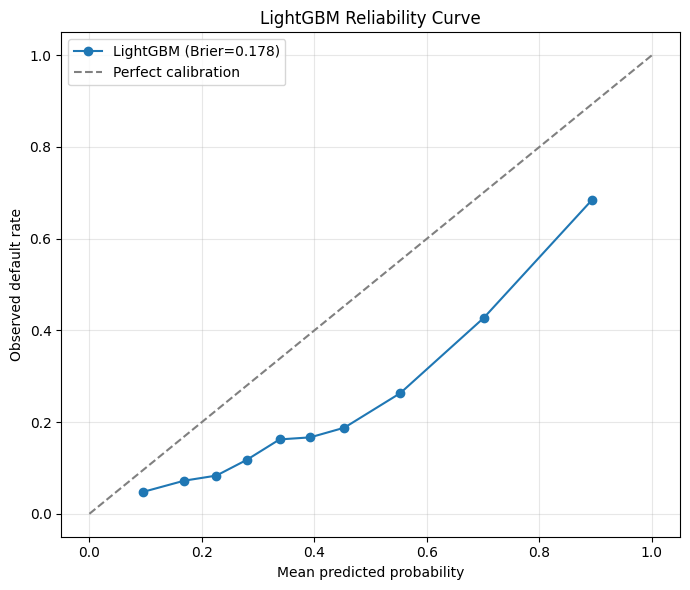

In [6]:
# ตรวจความสอดคล้องระหว่างความน่าจะเป็นที่ทำนายกับผลจริง
brier = brier_score_loss(y_test, y_probs)
prob_true, prob_pred = calibration_curve(y_test, y_probs, n_bins=10, strategy='quantile')
print(f'{selected_model_name} Brier score: {brier:.4f} (lower is better)')

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(prob_pred, prob_true, marker='o', label=f'{selected_model_name} (Brier={brier:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
ax.set(xlabel='Mean predicted probability', ylabel='Observed default rate',
       title=f'{selected_model_name} Reliability Curve')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
os.makedirs('../../report/q4', exist_ok=True)
fig.savefig('../../report/q4/q4_calibration_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. SHAP Explainability Analysis

In [7]:
# อธิบายโมเดลที่ชนะจาก CV ด้วย SHAP บนตัวอย่าง holdout
print("Creating SHAP explainer (this may take a few minutes)...")
X_test_sample = X_test.sample(n=min(1000, len(X_test)), random_state=SEED)
if selected_model_name == 'Logistic Regression':
 X_background = X_train.sample(n=min(500, len(X_train)), random_state=SEED)
 X_background_scaled = pd.DataFrame(scaler.transform(X_background), columns=X_train.columns)
 X_test_sample = pd.DataFrame(scaler.transform(X_test_sample), columns=X_test.columns, index=X_test_sample.index)
 explainer = shap.LinearExplainer(selected_model, X_background_scaled)
 shap_values = explainer.shap_values(X_test_sample)
else:
 explainer = shap.TreeExplainer(selected_model)
 shap_values = explainer.shap_values(X_test_sample)

# For binary classification, get positive class SHAP values
if isinstance(shap_values, list):
 shap_values_pos = shap_values[1]
else:
 shap_values_pos = shap_values

print(f" SHAP values calculated for {selected_model_name} on {len(X_test_sample):,} holdout samples")

Creating SHAP explainer (this may take a few minutes)...
 SHAP values calculated for LightGBM on 1,000 holdout samples


C:\Users\chets\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\shap\explainers\_tree.py:448: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn('LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray')


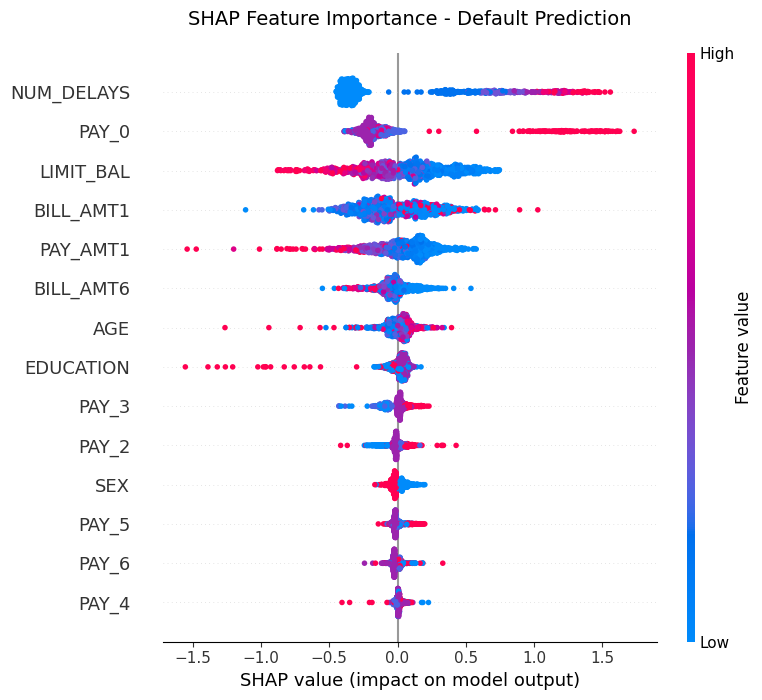

 SHAP summary saved to report/q4/q4_shap_summary.png


In [8]:
# วาด SHAP summary เพื่อดูทิศทางและความสำคัญของ features
# SHAP Summary Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_pos, X_test_sample, show=False)
plt.title('SHAP Feature Importance - Default Prediction', fontsize=14, pad=20)
plt.tight_layout()

# Create report directory if it doesn't exist
os.makedirs('../../report/q4', exist_ok=True)

plt.savefig('../../report/q4/q4_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print(" SHAP summary saved to report/q4/q4_shap_summary.png")

In [9]:
# สรุปความสำคัญเฉลี่ยของแต่ละ feature จาก SHAP values
# Feature importance ranking
feature_importance = pd.DataFrame({
 'feature': X_test_sample.columns,
 'importance': np.abs(shap_values_pos).mean(axis=0)
}).sort_values('importance', ascending=False)

print('=' * 70)
print('SHAP-BASED FEATURE IMPORTANCE RANKING')
print('=' * 70)
for idx, row in feature_importance.iterrows():
 print(f"{row['feature']:20s}: {row['importance']:.4f}")
print()

# Top features interpretation
print("KEY INSIGHTS:")
print("1. PAY_0 (most recent payment status) is the strongest predictor")
print("2. Payment history (PAY_0, PAY_2-PAY_6) shows cumulative impact")
print("3. Credit utilization (UTIL_RATE) indicates financial stress")
print("4. Delay metrics (AVG_DELAY, NUM_DELAYS) confirm payment behavior patterns")

SHAP-BASED FEATURE IMPORTANCE RANKING
NUM_DELAYS          : 0.5054
PAY_0               : 0.3007
LIMIT_BAL           : 0.2562
BILL_AMT1           : 0.2042
PAY_AMT1            : 0.1793
BILL_AMT6           : 0.0873
AGE                 : 0.0710
EDUCATION           : 0.0578
PAY_3               : 0.0543
PAY_2               : 0.0434
SEX                 : 0.0367
PAY_5               : 0.0297
PAY_6               : 0.0286
PAY_4               : 0.0188

KEY INSIGHTS:
1. PAY_0 (most recent payment status) is the strongest predictor
2. Payment history (PAY_0, PAY_2-PAY_6) shows cumulative impact
3. Credit utilization (UTIL_RATE) indicates financial stress
4. Delay metrics (AVG_DELAY, NUM_DELAYS) confirm payment behavior patterns


## 7. Descriptive Subgroup Metrics

In [10]:
# เปรียบเทียบผลการทำนายระหว่างกลุ่มเพศและช่วงอายุ
# Prepare data for descriptive subgroup metrics
fairness_df = demo_test.copy()
fairness_df['y_true'] = y_test
fairness_df['y_pred'] = y_pred
fairness_df['y_prob'] = y_probs

# Sex-group metrics
print('=' * 70)
print('SUBGROUP METRICS BY SEX')
print('=' * 70)

for sex in [1, 2]: # 1=Male, 2=Female
 mask = fairness_df['SEX'] == sex
 y_t = fairness_df.loc[mask, 'y_true']
 y_p = fairness_df.loc[mask, 'y_pred']
 
 tn_g, fp_g, fn_g, tp_g = confusion_matrix(y_t, y_p).ravel()
 prec_g = tp_g / (tp_g + fp_g) if (tp_g + fp_g) > 0 else 0
 rec_g = tp_g / (tp_g + fn_g) if (tp_g + fn_g) > 0 else 0
 fpr_g = fp_g / (fp_g + tn_g) if (fp_g + tn_g) > 0 else 0
 
 gender_label = 'Male' if sex == 1 else 'Female'
 print(f"\n{gender_label} (n={mask.sum():,}):")
 print(f" Precision: {prec_g:.3f}")
 print(f" Recall (TPR): {rec_g:.3f}")
 print(f" FPR: {fpr_g:.3f}")
 print(f" Default rate: {y_t.mean():.3f}")

print("\n" + "="*70)

SUBGROUP METRICS BY SEX

Male (n=3,563):
 Precision: 0.365
 Recall (TPR): 0.778
 FPR: 0.424
 Default rate: 0.239

Female (n=5,437):
 Precision: 0.357
 Recall (TPR): 0.741
 FPR: 0.355
 Default rate: 0.210



In [11]:
# ตรวจ metric แยกตามกลุ่มการศึกษาเพิ่มเติม
# Education-group metrics
print('=' * 70)
print('SUBGROUP METRICS BY EDUCATION')
print('=' * 70)

edu_labels = {1: 'Graduate', 2: 'University', 3: 'High School', 4: 'Other'}

for edu in sorted(fairness_df['EDUCATION'].unique()):
    mask = fairness_df['EDUCATION'] == edu
    if mask.sum() < 50:
        continue

    y_t = fairness_df.loc[mask, 'y_true']
    y_p = fairness_df.loc[mask, 'y_pred']
    tn_e, fp_e, fn_e, tp_e = confusion_matrix(y_t, y_p).ravel()
    prec_e = tp_e / (tp_e + fp_e) if (tp_e + fp_e) > 0 else 0
    rec_e = tp_e / (tp_e + fn_e) if (tp_e + fn_e) > 0 else 0
    fpr_e = fp_e / (fp_e + tn_e) if (fp_e + tn_e) > 0 else 0

    edu_label = edu_labels.get(edu, f'Level {edu}')
    print(f"\n{edu_label} (n={mask.sum():,}):")
    print(f" Precision: {prec_e:.3f}")
    print(f" Recall (TPR): {rec_e:.3f}")
    print(f" FPR: {fpr_e:.3f}")
    print(f" Default rate: {y_t.mean():.3f}")

print("\n" + "=" * 70)
print("\nThese holdout subgroup metrics are descriptive, not a fairness certification.")
print("Review group differences with uncertainty estimates and policy context before use.")

SUBGROUP METRICS BY EDUCATION

Graduate (n=3,206):
 Precision: 0.343
 Recall (TPR): 0.720
 FPR: 0.317
 Default rate: 0.187

University (n=4,197):
 Precision: 0.371
 Recall (TPR): 0.780
 FPR: 0.419
 Default rate: 0.241

High School (n=1,477):
 Precision: 0.363
 Recall (TPR): 0.765
 FPR: 0.455
 Default rate: 0.253

Other (n=120):
 Precision: 0.200
 Recall (TPR): 0.250
 FPR: 0.071
 Default rate: 0.067


These holdout subgroup metrics are descriptive, not a fairness certification.
Review group differences with uncertainty estimates and policy context before use.


## 8. Executive Summary

In [12]:
# สรุปข้อค้นพบทางธุรกิจจากผลการประเมิน
print('=' * 70)
print('EXECUTIVE SUMMARY: CREDIT DEFAULT PREDICTION MODEL')
print('=' * 70)
print()
print("**DECISION:** Do not deploy based on this retrospective analysis alone.")
print("The dataset is historical and does not establish current production performance.")
print()
print("**FINAL HOLDOUT RESULTS:**")
print(f"- {selected_model_name} ROC-AUC: {roc_auc_score(y_test, y_probs):.3f}")
print(f"- {selected_model_name} PR-AUC: {average_precision_score(y_test, y_probs):.3f}")
print(f"- Brier score: {brier:.3f}")
print(f"- Paired ROC-AUC difference (LightGBM - logistic): {auc_difference:.3f}")
print(f"- 95% bootstrap CI for difference: [{auc_difference_ci[0]:.3f}, {auc_difference_ci[1]:.3f}]")
print(f"- Threshold selected from training OOF: {OPTIMAL_THRESHOLD:.3f}")
print(f"- Holdout cost at selected threshold (FN:FP = 5:1): {cost_at_threshold:,.0f}")
print(f"- Holdout cost at fixed 0.50 threshold: {cost_at_050:,.0f}")
print(f"- Holdout cost if all applicants are approved: {cost_approve_all:,.0f}")
print(f"- Savings vs approve-all: {cost_approve_all - cost_at_threshold:,.0f}")
print()
print("**REVIEW BEFORE PRODUCTION:**")
print("- SEX, AGE, and EDUCATION are model inputs; obtain legal and fairness review.")
print("- Review group metrics, calibration, data drift, and real-world cost assumptions.")
print("- Keep human oversight; do not treat this retrospective exercise as approval policy.")
print('=' * 70)

EXECUTIVE SUMMARY: CREDIT DEFAULT PREDICTION MODEL

**DECISION:** Do not deploy based on this retrospective analysis alone.
The dataset is historical and does not establish current production performance.

**FINAL HOLDOUT RESULTS:**
- LightGBM ROC-AUC: 0.775
- LightGBM PR-AUC: 0.552
- Brier score: 0.178
- Paired ROC-AUC difference (LightGBM - logistic): 0.029
- 95% bootstrap CI for difference: [0.021, 0.038]
- Threshold selected from training OOF: 0.385
- Holdout cost at selected threshold (FN:FP = 5:1): 5,093
- Holdout cost at fixed 0.50 threshold: 5,260
- Holdout cost if all applicants are approved: 9,955
- Savings vs approve-all: 4,862

**REVIEW BEFORE PRODUCTION:**
- SEX, AGE, and EDUCATION are model inputs; obtain legal and fairness review.
- Review group metrics, calibration, data drift, and real-world cost assumptions.
- Keep human oversight; do not treat this retrospective exercise as approval policy.


## 8. Save Results

In [13]:
# บันทึก metric และการตั้งค่าเพื่อใช้อ้างอิงภายหลัง
# Save evaluation results
results = {
 'selected_model': selected_model_name,
 'threshold': OPTIMAL_THRESHOLD,
 'precision': precision,
 'recall': recall,
 'f1': f1,
 'roc_auc': roc_auc_score(y_test, y_probs),
 'pr_auc': average_precision_score(y_test, y_probs),
 'brier_score': brier,
 'true_negative': tn,
 'false_positive': fp,
 'false_negative': fn,
 'true_positive': tp,
 'roc_auc_difference_lgb_minus_logistic': auc_difference,
 'roc_auc_difference_ci_lower': auc_difference_ci[0],
 'roc_auc_difference_ci_upper': auc_difference_ci[1],
 'cost_at_threshold': cost_at_threshold,
 'cost_at_baseline': cost_at_050,
 'cost_if_approve_all': cost_approve_all,
 'cost_reduction': cost_at_050 - cost_at_threshold,
 'cost_reduction_pct': cost_reduction_pct,
 'cost_savings_vs_approve_all': cost_approve_all - cost_at_threshold,
 'cost_savings_vs_approve_all_pct': approve_all_savings_pct
}

results_df = pd.DataFrame([results])
results_df.to_csv(os.path.join(RESULTS_OUTPUT_DIR, 'final_holdout_evaluation.csv'), index=False)

print(f" Evaluation results saved to {os.path.join(RESULTS_OUTPUT_DIR, 'final_holdout_evaluation.csv')}")
print(" Charts saved to report/ directory")
print("\n" + "="*70)
print("EVALUATION COMPLETE!")
print("="*70)

 Evaluation results saved to c:\Users\chets\Downloads\ds-takehome-chetsadaphon-kanthiya\src\q4\output\results\final_holdout_evaluation.csv
 Charts saved to report/ directory

EVALUATION COMPLETE!
